# 沪深300 Variational Bayesian HMM 择时策略

本 notebook 单独研究 **Variational Bayesian HMM** 在沪深300指数择时中的应用。

和普通 EM-HMM 的区别是：

- EM-HMM：寻找一组最大似然参数 `lambda_hat = (pi, A, B)`；
- Variational Bayesian HMM：用变分推理近似参数和隐藏状态的后验分布，从而得到更稳定的状态转移与观测分布估计。

这里使用 `hmmlearn.vhmm.VariationalGaussianHMM` 实现。策略流程：

1. 获取沪深300日频数据；
2. 构造持仓周期观测变量；
3. 用过去固定窗口训练 Variational Gaussian HMM；
4. 用当前隐藏状态和转移矩阵估计未来持仓周期 `expected_ret`；
5. 若 `expected_ret > 0`，持有沪深300；否则空仓；
6. 与沪深300买入持有基准比较。


## 1. 依赖、代理与参数


In [329]:
import os
import warnings
import logging
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", message="Model is not converging")
logging.getLogger("hmmlearn").setLevel(logging.ERROR)

plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25


In [330]:
# 国内 AkShare 数据源通常不需要代理，甚至走代理会报错。
PROXY_ENV_KEYS = [
    "HTTP_PROXY", "HTTPS_PROXY", "http_proxy", "https_proxy", "ALL_PROXY", "all_proxy",
]


def clear_python_proxy():
    for key in PROXY_ENV_KEYS:
        os.environ.pop(key, None)
    os.environ["NO_PROXY"] = "*"
    os.environ["no_proxy"] = "*"


clear_python_proxy()
print("Python proxy cleared for AkShare China data.")


Python proxy cleared for AkShare China data.


In [331]:
try:
    from hmmlearn.vhmm import VariationalGaussianHMM
except Exception as exc:
    raise ImportError(
        "当前环境的 hmmlearn 不支持 VariationalGaussianHMM。"
        "请先运行：pip install -U hmmlearn"
    ) from exc


@dataclass
class VBHMMConfig:
    start_date: str = "2010-01-01"
    end_date: str = "2026-05-31"
    symbol: str = "sh000852"
    holding_period: int = 15
    n_states: int = 5
    train_window_days: int = 2000
    retrain_mode: str = "each_rebalance"  # "each_rebalance" 或 "quarterly"
    n_iter: int = 300
    tol: float = 1e-3
    n_restarts: int = 3
    random_state: int = 42
    transaction_fee: float = 0.0


cfg = VBHMMConfig()
FEATURE_COLS = ["ret_h", "sharpe_h", "vol_ratio", "ret_half"]
cfg


VBHMMConfig(start_date='2010-01-01', end_date='2026-05-31', symbol='sh000852', holding_period=15, n_states=5, train_window_days=2000, retrain_mode='each_rebalance', n_iter=300, tol=0.001, n_restarts=3, random_state=42, transaction_fee=0.0)

## 2. 获取沪深300数据


In [332]:
import akshare as ak


def load_hs300_daily(cfg):
    raw = ak.stock_zh_index_daily(symbol=cfg.symbol)
    df = raw.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.rename(columns={"close": "close", "volume": "volume"})
    df["close"] = pd.to_numeric(df["close"], errors="coerce")
    if "volume" in df.columns:
        df["volume"] = pd.to_numeric(df["volume"], errors="coerce")
    else:
        df["volume"] = np.nan
    df = df.sort_values("date")
    df = df[(df["date"] >= pd.to_datetime(cfg.start_date)) & (df["date"] <= pd.to_datetime(cfg.end_date))]
    df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=["date", "close"])
    return df[["date", "close", "volume"]].reset_index(drop=True)


daily = load_hs300_daily(cfg)
display(daily.head())
display(daily.tail())
print(daily.shape)


,date,close,volume
0,2014-10-17,6058.668,9712586400
1,2014-10-20,6154.520,7902498400
2,2014-10-21,6103.008,7954840800
3,2014-10-22,6027.510,7355880000
4,2014-10-23,5930.483,7429696000


,date,close,volume
2818,2026-05-25,8799.312,30289600600
2819,2026-05-26,8687.253,31437355100
2820,2026-05-27,8546.514,31311235400
2821,2026-05-28,8637.743,30074765000
2822,2026-05-29,8408.736,33278021700


(2823, 3)


## 3. 构造持仓周期观测变量

`holding_period` 由上面的 `cfg` 控制；当前每条样本代表一个持仓周期：

- `ret_h`：过去一个持仓周期的收益；
- `sharpe_h`：过去一个持仓周期的收益 / 波动率；
- `vol_ratio`：过去半周期成交量均值 / 全周期成交量均值；
- `ret_half`：过去半个持仓周期的收益；
- `future_ret`：未来一个持仓周期的收益，用于计算各隐藏状态对应的未来收益均值，不作为 HMM 输入。


In [333]:
def build_period_observations(daily, holding_period=40):
    df = daily.dropna(subset=["close"]).copy()
    df = df.sort_values("date").reset_index(drop=True)
    h = holding_period
    half_h = max(1, h // 2)

    rows = []
    for i in range(h, len(df) - h, h):
        date = df.loc[i, "date"]
        next_date = df.loc[i + h, "date"]

        p0 = df.loc[i - h, "close"]
        p1 = df.loc[i, "close"]
        p2 = df.loc[i + h, "close"]
        p_half = df.loc[i - half_h, "close"]

        ret_h = p1 / p0 - 1
        ret_half = p1 / p_half - 1
        future_ret = p2 / p1 - 1

        daily_ret_window = df.loc[i - h:i - 1, "close"].pct_change().dropna()
        vol = daily_ret_window.std()
        sharpe_h = ret_h / (vol * np.sqrt(h)) if vol and vol > 0 else 0.0

        if "volume" in df.columns and df["volume"].notna().sum() > h:
            full_vol = df.loc[i - h:i - 1, "volume"].mean()
            half_vol = df.loc[i - half_h:i - 1, "volume"].mean()
            vol_ratio = half_vol / full_vol if full_vol and full_vol > 0 else 1.0
        else:
            full_std = df.loc[i - h:i - 1, "close"].pct_change().std()
            half_std = df.loc[i - half_h:i - 1, "close"].pct_change().std()
            vol_ratio = half_std / full_std if full_std and full_std > 0 else 1.0

        rows.append(
            {
                "date": date,
                "next_date": next_date,
                "close": p1,
                "next_close": p2,
                "ret_h": ret_h,
                "sharpe_h": sharpe_h,
                "vol_ratio": vol_ratio,
                "ret_half": ret_half,
                "future_ret": future_ret,
            }
        )

    obs = pd.DataFrame(rows)
    obs = obs.replace([np.inf, -np.inf], np.nan).dropna()
    return obs


obs = build_period_observations(daily, cfg.holding_period)
display(obs.head())
display(obs.tail())
print(obs.shape)


,date,next_date,close,next_close,ret_h,sharpe_h,vol_ratio,ret_half,future_ret
0,2014-11-07,2014-11-28,6228.167,6478.108,0.027976,0.596073,1.100874,-0.002967,0.040131
1,2014-11-28,2014-12-19,6478.108,6438.042,0.040131,0.744671,1.087107,0.045942,-0.006185
2,2014-12-19,2015-01-13,6438.042,6167.117,-0.006185,-0.080707,0.897682,0.011188,-0.042082
3,2015-01-13,2015-02-03,6167.117,6654.549,-0.042082,-0.583346,0.970081,0.023160,0.079037
4,2015-02-03,2015-03-03,6654.549,7282.108,0.079037,1.267076,1.074110,0.023451,0.094305


,date,next_date,close,next_close,ret_h,sharpe_h,vol_ratio,ret_half,future_ret
182,2026-01-28,2026-02-26,8399.794,8490.617,0.062402,1.253182,0.948467,0.016230,0.010813
183,2026-02-26,2026-03-19,8490.617,7909.234,0.010813,0.168056,0.932104,0.031193,-0.068474
184,2026-03-19,2026-04-10,7909.234,7998.232,-0.068474,-1.164800,0.955894,-0.052797,0.011252
185,2026-04-10,2026-05-06,7998.232,8574.556,0.011252,0.121488,0.920868,0.049657,0.072056
186,2026-05-06,2026-05-27,8574.556,8546.514,0.072056,1.816779,1.035331,0.011003,-0.003270


(187, 9)


## 4. Variational Bayesian HMM 训练与预测

这里仍然使用滚动训练框架，但 HMM 模型换成 `VariationalGaussianHMM`。

预测逻辑：

```text
1. 用历史窗口训练 VB-HMM；
2. 解码当前隐藏状态 current_state；
3. 用转移矩阵 A[current_state] 得到下一期状态分布；
4. 用训练集中各状态对应的 future_ret 均值映射到 expected_ret；
5. expected_ret > 0 则持有沪深300，否则空仓。
```


In [334]:
def repair_transition_matrix(transmat):
    transmat = np.asarray(transmat, dtype=float).copy()
    transmat = np.nan_to_num(transmat, nan=0.0, posinf=0.0, neginf=0.0)
    n_states = transmat.shape[0]
    row_sum = transmat.sum(axis=1, keepdims=True)
    zero_rows = row_sum.squeeze() <= 1e-12
    if zero_rows.any():
        transmat[zero_rows, :] = 1.0 / n_states
        row_sum = transmat.sum(axis=1, keepdims=True)
    return transmat / row_sum


def fit_vb_hmm(X_train, n_states, cfg):
    best_model = None
    best_score = -np.inf
    last_error = None

    for j in range(cfg.n_restarts):
        model = VariationalGaussianHMM(
            n_components=n_states,
            covariance_type="diag",
            n_iter=cfg.n_iter,
            tol=cfg.tol,
            random_state=cfg.random_state + j,
        )
        try:
            model.fit(X_train)
            model.transmat_ = repair_transition_matrix(model.transmat_)
            score = model.score(X_train)
            if np.isfinite(score) and score > best_score:
                best_model = model
                best_score = score
        except Exception as exc:
            last_error = exc
            continue

    if best_model is None:
        raise RuntimeError(f"VB-HMM fitting failed. last_error={last_error}")
    return best_model


def train_vb_hmm_asof(obs, train_end_date, cfg):
    train_periods = max(20, cfg.train_window_days // cfg.holding_period)
    train = obs[obs["date"] < train_end_date].tail(train_periods).copy()
    train = train.replace([np.inf, -np.inf], np.nan).dropna(subset=FEATURE_COLS + ["future_ret"])

    if len(train) < max(30, cfg.n_states * 8):
        return None

    usable_features = [col for col in FEATURE_COLS if train[col].std(ddof=0) > 1e-10]
    if not usable_features:
        return None

    n_states_eff = min(cfg.n_states, max(2, len(train) // 10))

    scaler = StandardScaler()
    X_train = scaler.fit_transform(train[usable_features])
    if (not np.isfinite(X_train).all()) or np.nanstd(X_train) <= 1e-12:
        return None

    model = fit_vb_hmm(X_train, n_states_eff, cfg)
    train_states = model.predict(X_train)
    train["state"] = train_states

    state_mean = train.groupby("state")["future_ret"].mean()
    state_mean = state_mean.reindex(range(n_states_eff)).fillna(train["future_ret"].mean())
    state_win_rate = train.groupby("state")["future_ret"].apply(lambda x: (x > 0).mean())
    state_win_rate = state_win_rate.reindex(range(n_states_eff)).fillna((train["future_ret"] > 0).mean())

    return {
        "model": model,
        "scaler": scaler,
        "features": usable_features,
        "state_mean": state_mean,
        "state_win_rate": state_win_rate,
        "n_states_eff": n_states_eff,
        "train_start": train["date"].min(),
        "train_end": train["date"].max(),
    }


def predict_vb_hmm_asof(obs, date, fitted):
    current_hist = obs[obs["date"] <= date]
    if fitted is None or current_hist.empty:
        return np.nan, np.nan, np.nan, np.nan

    current = current_hist.iloc[-1]
    X_current = fitted["scaler"].transform(current[fitted["features"]].to_frame().T)
    current_state = int(fitted["model"].predict(X_current)[-1])
    transmat = repair_transition_matrix(fitted["model"].transmat_)
    next_state_prob = transmat[current_state]
    expected_ret = float(next_state_prob @ fitted["state_mean"].values)
    prob_up = float(next_state_prob @ fitted["state_win_rate"].values)
    signal = int(expected_ret > 0)
    return expected_ret, prob_up, signal, current_state


## 5. 滚动回测


In [335]:
if cfg.retrain_mode not in ["each_rebalance", "quarterly"]:
    raise ValueError("cfg.retrain_mode must be 'each_rebalance' or 'quarterly'")


def get_model_cache_key(date, cfg):
    if cfg.retrain_mode == "quarterly":
        return pd.Timestamp(date).to_period("Q")
    if cfg.retrain_mode == "each_rebalance":
        return pd.Timestamp(date)
    raise ValueError(cfg.retrain_mode)


rows = []
train_log = []
model_cache = {}

for _, current in obs.iterrows():
    date = current["date"]
    cache_key = get_model_cache_key(date, cfg)

    if cache_key not in model_cache:
        try:
            fitted = train_vb_hmm_asof(obs, date, cfg)
        except Exception as exc:
            print(f"Training failed {date}: {type(exc).__name__}: {exc}")
            fitted = None
        model_cache[cache_key] = fitted
        if fitted is not None:
            train_log.append(
                {
                    "cache_key": str(cache_key),
                    "asof_date": date,
                    "train_start": fitted["train_start"],
                    "train_end": fitted["train_end"],
                    "n_states_eff": fitted["n_states_eff"],
                    "n_features_eff": len(fitted["features"]),
                }
            )

    fitted = model_cache[cache_key]
    expected_ret, prob_up, signal, current_state = predict_vb_hmm_asof(obs, date, fitted)

    if pd.isna(signal):
        continue

    rows.append(
        {
            "date": date,
            "next_date": current["next_date"],
            "expected_ret": expected_ret,
            "prob_up": prob_up,
            "signal": signal,
            "current_state": current_state,
            "future_ret": current["future_ret"],
        }
    )

pred = pd.DataFrame(rows)
train_log = pd.DataFrame(train_log)
display(train_log.tail())
display(pred.head())
display(pred.tail())
print(pred.shape)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2371: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: 

Training failed 2018-11-06 00:00:00: RuntimeError: VB-HMM fitting failed. last_error=None


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: Runti

,cache_key,asof_date,train_start,train_end,n_states_eff,n_features_eff
141,2026-01-28 00:00:00,2026-01-28,2017-11-10,2026-01-07,5,4
142,2026-02-26 00:00:00,2026-02-26,2017-12-01,2026-01-28,5,4
143,2026-03-19 00:00:00,2026-03-19,2017-12-22,2026-02-26,5,4
144,2026-04-10 00:00:00,2026-04-10,2018-01-15,2026-03-19,5,4
145,2026-05-06 00:00:00,2026-05-06,2018-02-05,2026-04-10,5,4


,date,next_date,expected_ret,prob_up,signal,current_state,future_ret
0,2017-04-25,2017-05-17,0.015649,0.562813,1,3,-0.019881
1,2017-05-17,2017-06-09,0.014067,0.527280,1,0,-0.029314
2,2017-06-09,2017-06-30,0.021767,0.561184,1,2,0.015954
3,2017-06-30,2017-07-21,0.026773,0.593141,1,3,-0.028538
4,2017-07-21,2017-08-11,0.018012,0.550229,1,3,0.010437


,date,next_date,expected_ret,prob_up,signal,current_state,future_ret
141,2026-01-28,2026-02-26,0.004314,0.541387,1,1,0.010813
142,2026-02-26,2026-03-19,0.004819,0.544805,1,3,-0.068474
143,2026-03-19,2026-04-10,0.003833,0.546261,1,3,0.011252
144,2026-04-10,2026-05-06,0.002428,0.546896,1,4,0.072056
145,2026-05-06,2026-05-27,0.005071,0.555066,1,3,-0.003270


(146, 7)


## 6. 策略绩效


In [336]:
def max_drawdown(nav):
    nav = pd.Series(nav).dropna()
    dd = nav / nav.cummax() - 1
    return -dd.min()


def summarize_strategy(ret, nav, periods_per_year):
    ret = pd.Series(ret).dropna()
    nav = pd.Series(nav).dropna()
    ann_ret = nav.iloc[-1] ** (periods_per_year / len(ret)) - 1
    ann_vol = ret.std() * np.sqrt(periods_per_year)
    sharpe = ann_ret / ann_vol if ann_vol > 0 else np.nan
    return {
        "夏普比率": sharpe,
        "年化收益率": ann_ret,
        "总收益率": nav.iloc[-1] - 1,
        "最大回撤": max_drawdown(nav),
        "胜率": (ret > 0).mean(),
    }


bt = pred.copy()
bt["strategy_ret"] = bt["signal"] * bt["future_ret"]
bt["turnover"] = bt["signal"].diff().abs().fillna(bt["signal"].abs())
bt["strategy_ret"] = bt["strategy_ret"] - cfg.transaction_fee * bt["turnover"]
bt["benchmark_ret"] = bt["future_ret"]
bt["strategy_nav"] = (1 + bt["strategy_ret"]).cumprod()
bt["benchmark_nav"] = (1 + bt["benchmark_ret"]).cumprod()
bt["correct"] = np.sign(bt["expected_ret"]) == np.sign(bt["future_ret"])

periods_per_year = 252 / cfg.holding_period
summary = pd.DataFrame(
    [
        summarize_strategy(bt["strategy_ret"], bt["strategy_nav"], periods_per_year),
        summarize_strategy(bt["benchmark_ret"], bt["benchmark_nav"], periods_per_year),
    ],
    index=["VB-HMM 择时", "沪深300买入持有"],
)

display(summary)
display(bt.head())


,夏普比率,年化收益率,总收益率,最大回撤,胜率
VB-HMM 择时,0.152972,0.032672,0.322326,0.401306,0.417808
沪深300买入持有,0.037950,0.009993,0.090256,0.457157,0.520548


,date,next_date,expected_ret,prob_up,signal,current_state,future_ret,strategy_ret,turnover,benchmark_ret,strategy_nav,benchmark_nav,correct
0,2017-04-25,2017-05-17,0.015649,0.562813,1,3,-0.019881,-0.019881,1.0,-0.019881,0.980119,0.980119,False
1,2017-05-17,2017-06-09,0.014067,0.527280,1,0,-0.029314,-0.029314,0.0,-0.029314,0.951388,0.951388,False
2,2017-06-09,2017-06-30,0.021767,0.561184,1,2,0.015954,0.015954,0.0,0.015954,0.966567,0.966567,True
3,2017-06-30,2017-07-21,0.026773,0.593141,1,3,-0.028538,-0.028538,0.0,-0.028538,0.938983,0.938983,False
4,2017-07-21,2017-08-11,0.018012,0.550229,1,3,0.010437,0.010437,0.0,0.010437,0.948783,0.948783,True


## 7. 方向预测诊断


In [337]:
# correct 表示 expected_ret 和 future_ret 的方向是否一致。
# 这里的方向准确率不是交易胜率，而是模型对未来持仓周期收益方向的判断准确率。
bt["expected_direction"] = np.where(bt["expected_ret"] > 0, "预测上涨", "预测下跌/空仓")
bt["realized_direction"] = np.where(bt["future_ret"] > 0, "实际上涨", "实际下跌/不涨")
bt["correct"] = ((bt["expected_ret"] > 0) & (bt["future_ret"] > 0)) | (
    (bt["expected_ret"] <= 0) & (bt["future_ret"] <= 0)
)

direction_summary = pd.DataFrame(
    {
        "样本数": [len(bt)],
        "方向准确率": [bt["correct"].mean()],
        "预测上涨比例": [(bt["expected_ret"] > 0).mean()],
        "实际上涨比例": [(bt["future_ret"] > 0).mean()],
        "上涨期参与率": [bt.loc[bt["future_ret"] > 0, "signal"].mean()],
        "下跌期空仓率": [1 - bt.loc[bt["future_ret"] <= 0, "signal"].mean()],
        "预测上涨后平均未来收益": [bt.loc[bt["expected_ret"] > 0, "future_ret"].mean()],
        "预测下跌/空仓后平均未来收益": [bt.loc[bt["expected_ret"] <= 0, "future_ret"].mean()],
    }
)
display(direction_summary)

direction_table = pd.crosstab(
    bt["realized_direction"],
    bt["expected_direction"],
    margins=True,
    margins_name="合计",
)
display(direction_table)

direction_rate_table = pd.crosstab(
    bt["realized_direction"],
    bt["expected_direction"],
    normalize="index",
)
display(direction_rate_table)


,样本数,方向准确率,预测上涨比例,实际上涨比例,上涨期参与率,下跌期空仓率,预测上涨后平均未来收益,预测下跌/空仓后平均未来收益
0,146,0.609589,0.705479,0.520548,0.802632,0.4,0.004577,-0.002199


expected_direction,预测上涨,预测下跌/空仓,合计
realized_direction,,,
实际上涨,61,15,76
实际下跌/不涨,42,28,70
合计,103,43,146


expected_direction,预测上涨,预测下跌/空仓
realized_direction,,
实际上涨,0.802632,0.197368
实际下跌/不涨,0.600000,0.400000


## 8. 下跌幅度分层与 expected_ret 单调性检验


,future_ret_bucket,样本数,预测上涨比例,持仓比例,平均预期收益,平均未来收益,平均策略收益
0,大跌(<-5%),27,0.666667,0.666667,0.002463,-0.082672,-0.055471
1,小跌/不涨(-5%~0),43,0.558140,0.558140,0.003420,-0.020228,-0.011224
2,上涨(>0),76,0.802632,0.802632,0.004626,0.045774,0.032260


/Users/zhu/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 22823 (\N{CJK UNIFIED IDEOGRAPH-5927}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/zhu/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 36300 (\N{CJK UNIFIED IDEOGRAPH-8DCC}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/zhu/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 23567 (\N{CJK UNIFIED IDEOGRAPH-5C0F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/zhu/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 19981 (\N{CJK UNIFIED IDEOGRAPH-4E0D}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/zhu/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 28072

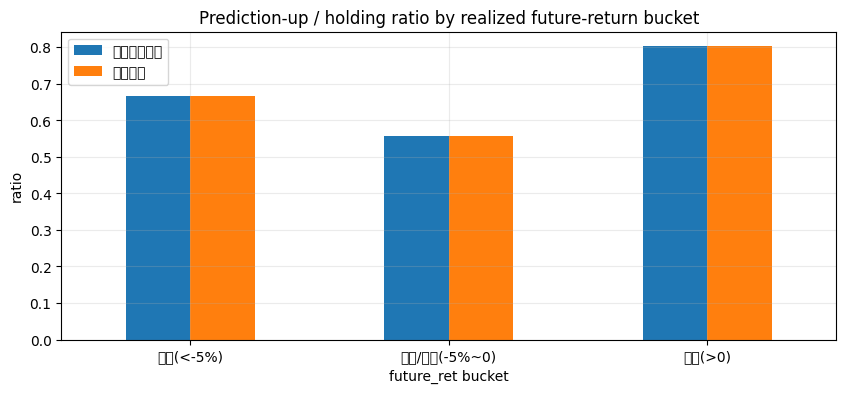

In [338]:
# 下跌幅度分层：重点看模型是不是只会乐观，还是至少能避开大跌。
bt["future_ret_bucket"] = pd.cut(
    bt["future_ret"],
    bins=[-np.inf, -0.05, 0, np.inf],
    labels=["大跌(<-5%)", "小跌/不涨(-5%~0)", "上涨(>0)"],
)

bucket_diag = (
    bt.groupby("future_ret_bucket", observed=True)
    .agg(
        样本数=("future_ret", "size"),
        预测上涨比例=("expected_ret", lambda x: (x > 0).mean()),
        持仓比例=("signal", "mean"),
        平均预期收益=("expected_ret", "mean"),
        平均未来收益=("future_ret", "mean"),
        平均策略收益=("strategy_ret", "mean"),
    )
    .reset_index()
)
display(bucket_diag)

fig, ax = plt.subplots(figsize=(10, 4))
bucket_diag.plot(
    x="future_ret_bucket",
    y=["预测上涨比例", "持仓比例"],
    kind="bar",
    ax=ax,
)
ax.set_title("Prediction-up / holding ratio by realized future-return bucket")
ax.set_xlabel("future_ret bucket")
ax.set_ylabel("ratio")
ax.tick_params(axis="x", rotation=0)
plt.show()


,expected_ret_group,样本数,平均预期收益,平均未来收益,未来收益中位数,未来上涨胜率,持仓比例,平均策略收益
0,"(-0.0159, -0.000935]",30,-0.003863,-0.000532,-0.011767,0.366667,0.000000,0.000000
1,"(-0.000935, 0.00209]",29,0.000428,0.005675,0.006250,0.551724,0.551724,0.008386
2,"(0.00209, 0.00453]",29,0.003393,-0.001787,0.005578,0.551724,1.000000,-0.001787
3,"(0.00453, 0.00692]",29,0.005871,-0.000288,0.005350,0.551724,1.000000,-0.000288
4,"(0.00692, 0.0273]",29,0.013793,0.009945,0.010110,0.586207,1.000000,0.009945


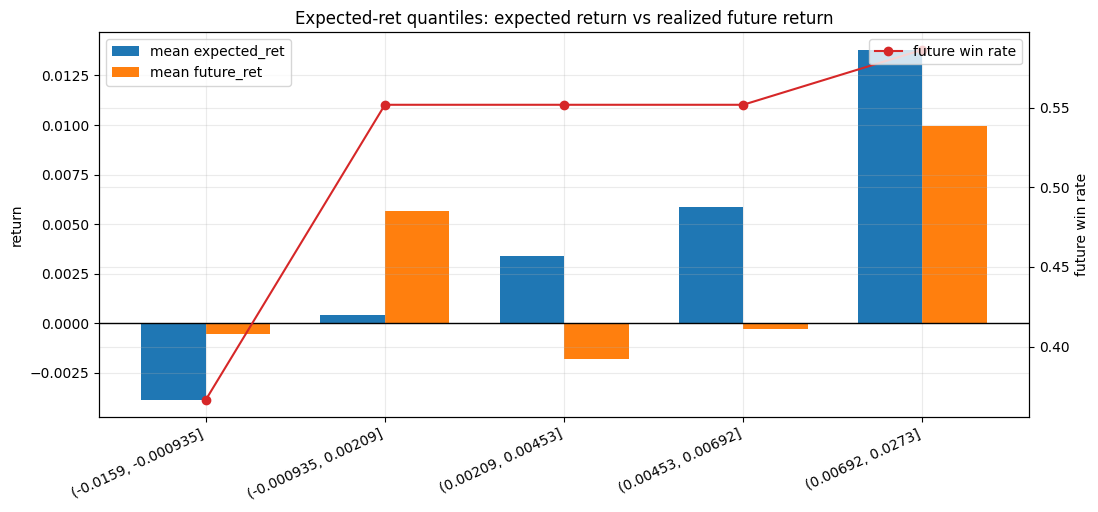

In [339]:
# expected_ret 单调性检验：
# 如果模型有排序能力，expected_ret 越高的组，未来收益均值和胜率也应该越高。
bt["expected_ret_group"] = pd.qcut(
    bt["expected_ret"],
    q=5,
    duplicates="drop",
)

expected_ret_monotonicity = (
    bt.groupby("expected_ret_group", observed=True)
    .agg(
        样本数=("future_ret", "size"),
        平均预期收益=("expected_ret", "mean"),
        平均未来收益=("future_ret", "mean"),
        未来收益中位数=("future_ret", "median"),
        未来上涨胜率=("future_ret", lambda x: (x > 0).mean()),
        持仓比例=("signal", "mean"),
        平均策略收益=("strategy_ret", "mean"),
    )
    .reset_index()
)
display(expected_ret_monotonicity)

fig, ax1 = plt.subplots(figsize=(12, 5))
x = np.arange(len(expected_ret_monotonicity))
ax1.bar(
    x - 0.18,
    expected_ret_monotonicity["平均预期收益"],
    width=0.36,
    label="mean expected_ret",
)
ax1.bar(
    x + 0.18,
    expected_ret_monotonicity["平均未来收益"],
    width=0.36,
    label="mean future_ret",
)
ax1.axhline(0, color="black", linewidth=1)
ax1.set_xticks(x)
ax1.set_xticklabels([str(v) for v in expected_ret_monotonicity["expected_ret_group"]], rotation=25, ha="right")
ax1.set_title("Expected-ret quantiles: expected return vs realized future return")
ax1.set_ylabel("return")
ax1.legend(loc="upper left")

ax2 = ax1.twinx()
ax2.plot(x, expected_ret_monotonicity["未来上涨胜率"], color="tab:red", marker="o", label="future win rate")
ax2.set_ylabel("future win rate")
ax2.legend(loc="upper right")
plt.show()


## 9. 可视化与状态诊断


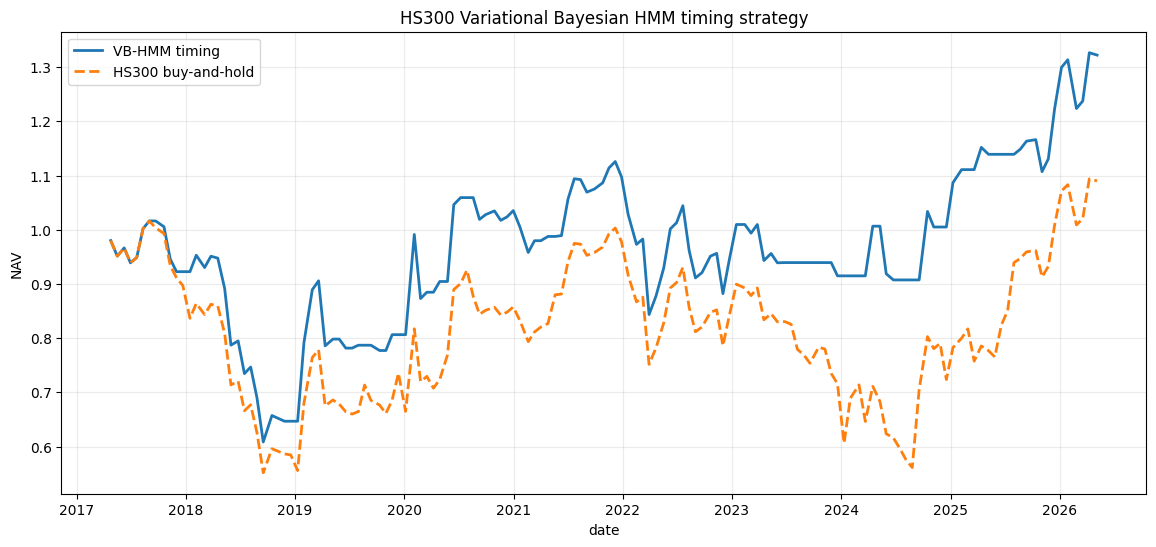

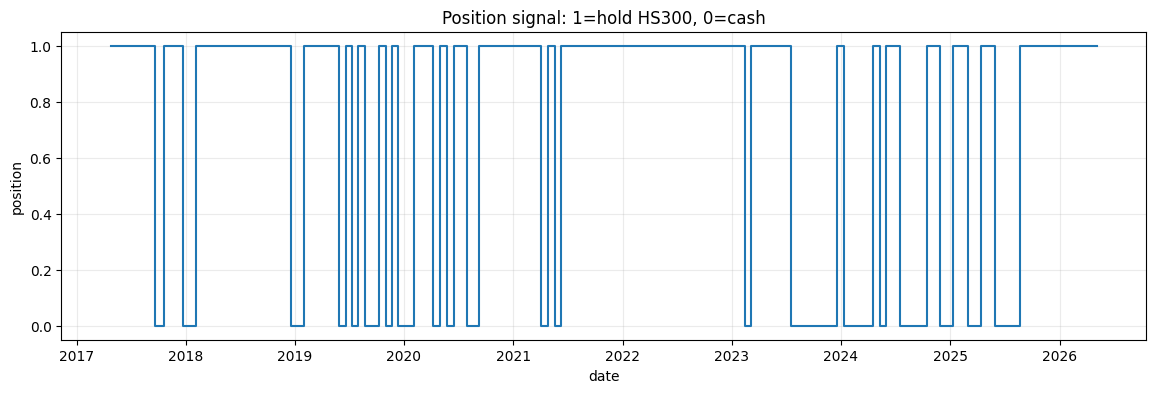

In [340]:
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(bt["date"], bt["strategy_nav"], label="VB-HMM timing", linewidth=2)
ax.plot(bt["date"], bt["benchmark_nav"], label="HS300 buy-and-hold", linestyle="--", linewidth=2)
ax.set_title("HS300 Variational Bayesian HMM timing strategy")
ax.set_xlabel("date")
ax.set_ylabel("NAV")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(bt["date"], bt["signal"], drawstyle="steps-post")
ax.set_title("Position signal: 1=hold HS300, 0=cash")
ax.set_xlabel("date")
ax.set_ylabel("position")
plt.show()


In [341]:
state_profile = (
    bt.groupby("current_state")
    .agg(
        n_observations=("current_state", "size"),
        expected_ret_mean=("expected_ret", "mean"),
        prob_up_mean=("prob_up", "mean"),
        future_ret_mean=("future_ret", "mean"),
        future_win_rate=("future_ret", lambda x: (x > 0).mean()),
    )
    .reset_index()
    .rename(columns={"current_state": "state"})
)
display(state_profile)

signal_diag = pd.DataFrame(
    {
        "signal_ratio": [bt["signal"].mean()],
        "mean_expected_ret": [bt["expected_ret"].mean()],
        "mean_prob_up": [bt["prob_up"].mean()],
        "prediction_accuracy": [bt["correct"].mean()],
        "trade_count": [bt["turnover"].sum() / 2],
    }
)
display(signal_diag)


,state,n_observations,expected_ret_mean,prob_up_mean,future_ret_mean,future_win_rate
0,0,24,0.003502,0.509494,0.000258,0.500000
1,1,30,0.002916,0.515664,0.003284,0.500000
2,2,33,0.004194,0.501239,0.000964,0.545455
3,3,33,0.006303,0.521388,0.002496,0.484848
4,4,26,0.001816,0.511702,0.006076,0.576923


,signal_ratio,mean_expected_ret,mean_prob_up,prediction_accuracy,trade_count
0,0.705479,0.003871,0.511978,0.609589,21.5


## 10. 同一套参数在不同指数上的横向测试


In [342]:
def run_vb_hmm_backtest_for_symbol(symbol, name, base_cfg):
    local_cfg = VBHMMConfig(
        start_date=base_cfg.start_date,
        end_date=base_cfg.end_date,
        symbol=symbol,
        holding_period=base_cfg.holding_period,
        n_states=base_cfg.n_states,
        train_window_days=base_cfg.train_window_days,
        retrain_mode=base_cfg.retrain_mode,
        n_iter=base_cfg.n_iter,
        tol=base_cfg.tol,
        n_restarts=base_cfg.n_restarts,
        random_state=base_cfg.random_state,
        transaction_fee=base_cfg.transaction_fee,
    )

    daily_i = load_hs300_daily(local_cfg)
    obs_i = build_period_observations(daily_i, local_cfg.holding_period)
    rows_i = []
    train_log_i = []
    model_cache_i = {}

    for _, current in obs_i.iterrows():
        date = current["date"]
        cache_key = get_model_cache_key(date, local_cfg)

        if cache_key not in model_cache_i:
            try:
                fitted = train_vb_hmm_asof(obs_i, date, local_cfg)
            except Exception as exc:
                fitted = None
            model_cache_i[cache_key] = fitted

            if fitted is not None:
                train_log_i.append(
                    {
                        "asset": name,
                        "cache_key": str(cache_key),
                        "asof_date": date,
                        "train_start": fitted["train_start"],
                        "train_end": fitted["train_end"],
                        "n_states_eff": fitted["n_states_eff"],
                        "n_features_eff": len(fitted["features"]),
                    }
                )

        fitted = model_cache_i[cache_key]
        expected_ret, prob_up, signal, current_state = predict_vb_hmm_asof(obs_i, date, fitted)
        if pd.isna(signal):
            continue

        rows_i.append(
            {
                "asset": name,
                "symbol": symbol,
                "date": date,
                "next_date": current["next_date"],
                "expected_ret": expected_ret,
                "prob_up": prob_up,
                "signal": signal,
                "current_state": current_state,
                "future_ret": current["future_ret"],
            }
        )

    pred_i = pd.DataFrame(rows_i)
    if pred_i.empty:
        return None, pd.DataFrame(train_log_i)

    bt_i = pred_i.copy()
    bt_i["strategy_ret"] = bt_i["signal"] * bt_i["future_ret"]
    bt_i["turnover"] = bt_i["signal"].diff().abs().fillna(bt_i["signal"].abs())
    bt_i["strategy_ret"] = bt_i["strategy_ret"] - local_cfg.transaction_fee * bt_i["turnover"]
    bt_i["benchmark_ret"] = bt_i["future_ret"]
    bt_i["strategy_nav"] = (1 + bt_i["strategy_ret"]).cumprod()
    bt_i["benchmark_nav"] = (1 + bt_i["benchmark_ret"]).cumprod()
    bt_i["correct"] = ((bt_i["expected_ret"] > 0) & (bt_i["future_ret"] > 0)) | (
        (bt_i["expected_ret"] <= 0) & (bt_i["future_ret"] <= 0)
    )

    periods_per_year_i = 252 / local_cfg.holding_period
    strategy_summary = summarize_strategy(bt_i["strategy_ret"], bt_i["strategy_nav"], periods_per_year_i)
    benchmark_summary = summarize_strategy(bt_i["benchmark_ret"], bt_i["benchmark_nav"], periods_per_year_i)

    future_up = bt_i["future_ret"] > 0
    future_down = bt_i["future_ret"] <= 0
    big_down = bt_i["future_ret"] < -0.05

    row = {
        "asset": name,
        "symbol": symbol,
        "n_periods": len(bt_i),
        "start": bt_i["date"].min(),
        "end": bt_i["date"].max(),
        "strategy_sharpe": strategy_summary["夏普比率"],
        "strategy_annual_return": strategy_summary["年化收益率"],
        "strategy_total_return": strategy_summary["总收益率"],
        "strategy_max_drawdown": strategy_summary["最大回撤"],
        "benchmark_sharpe": benchmark_summary["夏普比率"],
        "benchmark_annual_return": benchmark_summary["年化收益率"],
        "benchmark_total_return": benchmark_summary["总收益率"],
        "benchmark_max_drawdown": benchmark_summary["最大回撤"],
        "signal_ratio": bt_i["signal"].mean(),
        "direction_accuracy": bt_i["correct"].mean(),
        "up_participation_rate": bt_i.loc[future_up, "signal"].mean(),
        "down_cash_rate": 1 - bt_i.loc[future_down, "signal"].mean(),
        "big_down_cash_rate": 1 - bt_i.loc[big_down, "signal"].mean() if big_down.any() else np.nan,
        "big_down_count": int(big_down.sum()),
        "trade_count": bt_i["turnover"].sum() / 2,
        "mean_expected_ret": bt_i["expected_ret"].mean(),
        "mean_future_ret_when_signal_1": bt_i.loc[bt_i["signal"] == 1, "future_ret"].mean(),
        "mean_future_ret_when_signal_0": bt_i.loc[bt_i["signal"] == 0, "future_ret"].mean(),
    }
    return (row, bt_i), pd.DataFrame(train_log_i)


In [343]:
INDEX_POOL = {
    "上证50": "sh000016",
    "沪深300": "sh000300",
    "中证500": "sh000905",
    "中证800": "sh000906",
    "中证1000": "sh000852",
    "创业板指": "sz399006",
    "深证成指": "sz399001",
    "上证指数": "sh000001",
}

multi_asset_rows = []
multi_asset_bt = {}
multi_asset_train_logs = []

for asset_name, symbol in INDEX_POOL.items():
    print(f"Running {asset_name} / {symbol}")
    try:
        result, train_log_asset = run_vb_hmm_backtest_for_symbol(symbol, asset_name, cfg)
    except Exception as exc:
        print(f"  failed: {type(exc).__name__}: {exc}")
        continue

    if not train_log_asset.empty:
        multi_asset_train_logs.append(train_log_asset)

    if result is None:
        print("  skipped: no valid prediction rows")
        continue

    row, bt_asset = result
    multi_asset_rows.append(row)
    multi_asset_bt[asset_name] = bt_asset

multi_asset_summary = pd.DataFrame(multi_asset_rows)
multi_asset_train_log = (
    pd.concat(multi_asset_train_logs, ignore_index=True)
    if multi_asset_train_logs
    else pd.DataFrame()
)

display(
    multi_asset_summary.sort_values(
        ["strategy_sharpe", "strategy_annual_return"],
        ascending=False,
    )
)


Running 上证50 / sh000016


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: Runti

Running 沪深300 / sh000300


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: Runti

Running 中证500 / sh000905


...

Running 深证成指 / sz399001


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: Runti

Running 上证指数 / sh000001


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: Runti

,asset,symbol,n_periods,start,end,strategy_sharpe,strategy_annual_return,strategy_total_return,strategy_max_drawdown,benchmark_sharpe,...,signal_ratio,direction_accuracy,up_participation_rate,down_cash_rate,big_down_cash_rate,big_down_count,trade_count,mean_expected_ret,mean_future_ret_when_signal_1,mean_future_ret_when_signal_0
5,创业板指,sz399006,214,2012-12-11,2026-04-20,0.399073,0.116511,3.070839,0.578950,0.589038,...,0.873832,0.500000,0.838983,0.083333,0.128205,39,14.5,0.007900,0.010394,0.029760
1,沪深300,sh000300,224,2012-07-18,2026-04-28,0.349637,0.058655,1.138247,0.409683,0.252441,...,0.758929,0.584821,0.798450,0.294737,0.550000,20,25.5,0.002575,0.005614,0.000834
0,上证50,sh000016,224,2012-07-18,2026-04-28,0.233154,0.043027,0.753634,0.444490,0.204732,...,0.727679,0.517857,0.727273,0.271845,0.363636,22,22.0,0.001895,0.004798,0.001130
7,上证指数,sh000001,223,2012-07-18,2026-04-28,0.221647,0.033909,0.556803,0.442214,0.255559,...,0.668161,0.506726,0.656000,0.316327,0.647059,17,24.5,0.000912,0.004057,0.004028
6,深证成指,sz399001,180,2012-07-18,2026-04-28,0.159337,0.035677,0.455852,0.586103,0.363764,...,0.588889,0.544444,0.605263,0.439394,0.400000,25,33.5,0.000382,0.006285,0.010487
4,中证1000,sh000852,146,2017-04-25,2026-05-06,0.152972,0.032672,0.322326,0.401306,0.037950,...,0.705479,0.609589,0.802632,0.400000,0.333333,27,21.5,0.003871,0.004577,-0.002199
3,中证800,sh000906,210,2012-07-18,2026-04-28,0.143585,0.028784,0.425789,0.546407,0.345254,...,0.757143,0.538095,0.754098,0.238636,0.238095,21,24.5,0.002771,0.003875,0.012351
2,中证500,sh000905,138,2012-07-18,2026-04-28,0.057870,0.013337,0.114976,0.682293,0.340964,...,0.659420,0.478261,0.626667,0.301587,0.444444,18,18.5,0.002617,0.003891,0.016608


,strategy_sharpe,benchmark_sharpe,strategy_max_drawdown,benchmark_max_drawdown,up_participation_rate,down_cash_rate,big_down_cash_rate
asset,,,,,,,
上证50,0.233154,0.204732,0.444490,0.438175,0.727273,0.271845,0.363636
沪深300,0.349637,0.252441,0.409683,0.439678,0.798450,0.294737,0.550000
中证500,0.057870,0.340964,0.682293,0.664165,0.626667,0.301587,0.444444
中证800,0.143585,0.345254,0.546407,0.482181,0.754098,0.238636,0.238095
中证1000,0.152972,0.037950,0.401306,0.457157,0.802632,0.400000,0.333333
创业板指,0.399073,0.589038,0.578950,0.559710,0.838983,0.083333,0.128205
深证成指,0.159337,0.363764,0.586103,0.541721,0.605263,0.439394,0.400000
上证指数,0.221647,0.255559,0.442214,0.499685,0.656000,0.316327,0.647059


/var/folders/tn/sjz2s1qd5mb1sw272y_w9_mm0000gn/T/ipykernel_15833/185638771.py:24: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/tn/sjz2s1qd5mb1sw272y_w9_mm0000gn/T/ipykernel_15833/185638771.py:24: UserWarning: Glyph 35777 (\N{CJK UNIFIED IDEOGRAPH-8BC1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/tn/sjz2s1qd5mb1sw272y_w9_mm0000gn/T/ipykernel_15833/185638771.py:24: UserWarning: Glyph 27818 (\N{CJK UNIFIED IDEOGRAPH-6CAA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/tn/sjz2s1qd5mb1sw272y_w9_mm0000gn/T/ipykernel_15833/185638771.py:24: UserWarning: Glyph 28145 (\N{CJK UNIFIED IDEOGRAPH-6DF1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/tn/sjz2s1qd5mb1sw272y_w9_mm0000gn/T/ipykernel_15833/185638771.py:24: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E2D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/tn/sjz2s1qd5

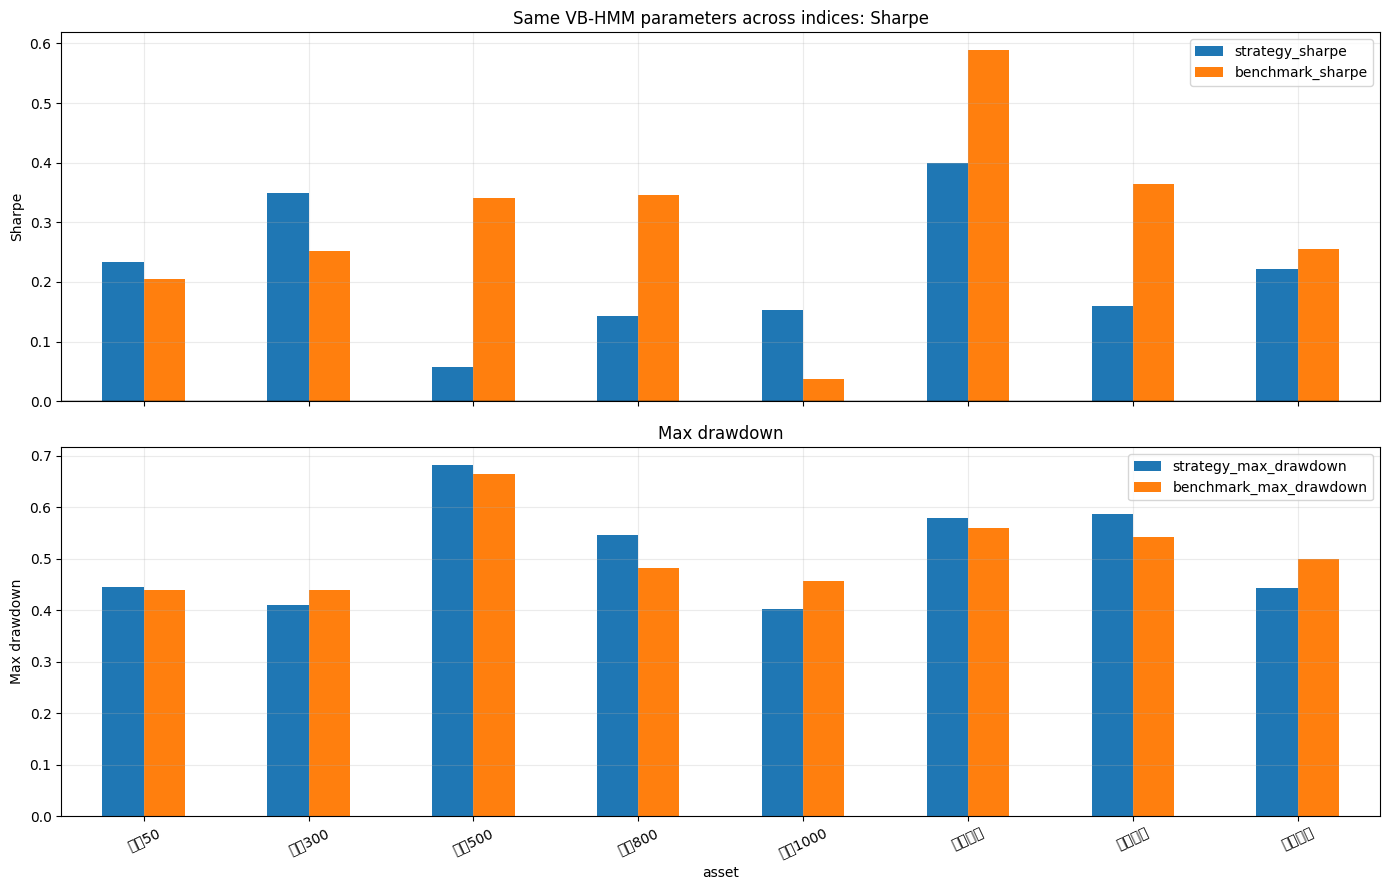

In [344]:
cols_to_plot = [
    "strategy_sharpe",
    "benchmark_sharpe",
    "strategy_max_drawdown",
    "benchmark_max_drawdown",
    "up_participation_rate",
    "down_cash_rate",
    "big_down_cash_rate",
]

display(multi_asset_summary[["asset", *cols_to_plot]].set_index("asset"))

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
plot_df = multi_asset_summary.set_index("asset")
plot_df[["strategy_sharpe", "benchmark_sharpe"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("Same VB-HMM parameters across indices: Sharpe")
axes[0].set_ylabel("Sharpe")
axes[0].axhline(0, color="black", linewidth=1)

plot_df[["strategy_max_drawdown", "benchmark_max_drawdown"]].plot(kind="bar", ax=axes[1])
axes[1].set_title("Max drawdown")
axes[1].set_ylabel("Max drawdown")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


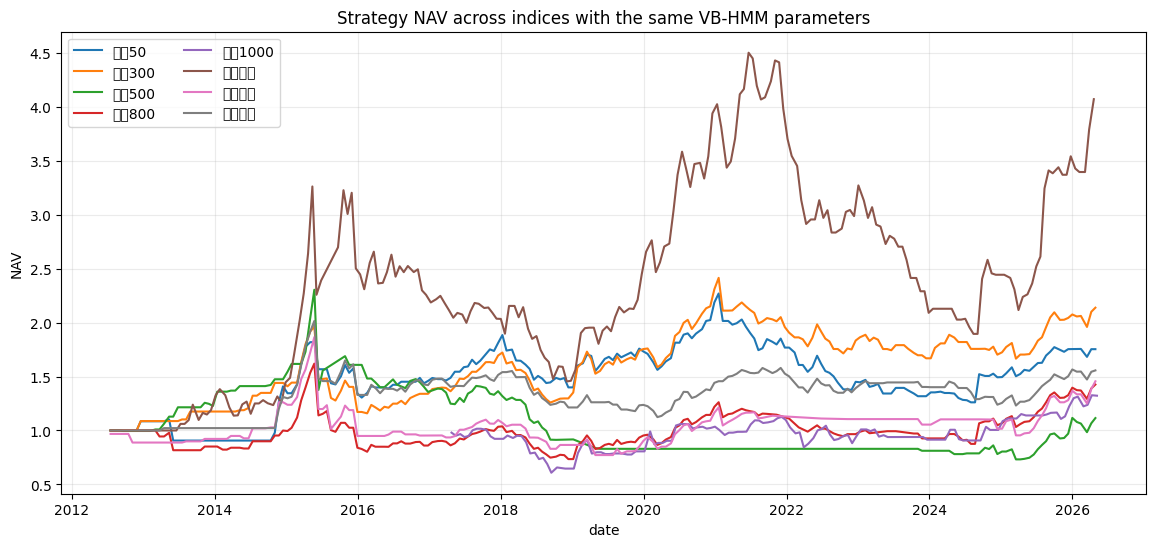

In [345]:
fig, ax = plt.subplots(figsize=(14, 6))
for asset_name, bt_asset in multi_asset_bt.items():
    ax.plot(bt_asset["date"], bt_asset["strategy_nav"], label=asset_name)
ax.set_title("Strategy NAV across indices with the same VB-HMM parameters")
ax.set_xlabel("date")
ax.set_ylabel("NAV")
ax.legend(ncol=2)
plt.show()


## 11. 中证1000：年度动态选参 walk-forward


In [346]:
# 目标：
# 每年年初，用过去 2 年作为参数验证窗口；
# 在候选参数网格中选择最近综合表现最好的一套；
# 下一整年固定使用这套超参数，但 HMM lambda 仍按 holding_period 滚动重训。

from itertools import product

WF_SYMBOL = "sh000852"
WF_ASSET_NAME = "中证1000"
WF_VALIDATION_YEARS = 2
WF_FIRST_TRADE_YEAR = 2018

# 为了计算量可控，先放一个中等大小网格；后续可以按需要扩展。
HOLDING_PERIOD_GRID = [10, 15, 20, 30]
N_STATES_GRID = [4, 5, 6]
TRAIN_WINDOW_GRID = [1500, 2000, 2500]


def make_cfg_for_params(symbol, holding_period, n_states, train_window_days, base_cfg):
    return VBHMMConfig(
        start_date=base_cfg.start_date,
        end_date=base_cfg.end_date,
        symbol=symbol,
        holding_period=holding_period,
        n_states=n_states,
        train_window_days=train_window_days,
        retrain_mode=base_cfg.retrain_mode,
        n_iter=base_cfg.n_iter,
        tol=base_cfg.tol,
        n_restarts=base_cfg.n_restarts,
        random_state=base_cfg.random_state,
        transaction_fee=base_cfg.transaction_fee,
    )


def summarize_bt_slice(bt_slice, holding_period):
    bt_slice = bt_slice.sort_values("date").copy()
    if bt_slice.empty:
        return None

    strategy_nav = (1 + bt_slice["strategy_ret"]).cumprod()
    benchmark_nav = (1 + bt_slice["benchmark_ret"]).cumprod()
    periods_per_year = 252 / holding_period
    strategy_summary = summarize_strategy(bt_slice["strategy_ret"], strategy_nav, periods_per_year)
    benchmark_summary = summarize_strategy(bt_slice["benchmark_ret"], benchmark_nav, periods_per_year)

    future_up = bt_slice["future_ret"] > 0
    future_down = bt_slice["future_ret"] <= 0
    big_down = bt_slice["future_ret"] < -0.05
    correct = ((bt_slice["expected_ret"] > 0) & (bt_slice["future_ret"] > 0)) | (
        (bt_slice["expected_ret"] <= 0) & (bt_slice["future_ret"] <= 0)
    )

    return {
        "n_periods": len(bt_slice),
        "strategy_sharpe": strategy_summary["夏普比率"],
        "strategy_annual_return": strategy_summary["年化收益率"],
        "strategy_total_return": strategy_summary["总收益率"],
        "strategy_max_drawdown": strategy_summary["最大回撤"],
        "benchmark_sharpe": benchmark_summary["夏普比率"],
        "benchmark_annual_return": benchmark_summary["年化收益率"],
        "benchmark_total_return": benchmark_summary["总收益率"],
        "benchmark_max_drawdown": benchmark_summary["最大回撤"],
        "signal_ratio": bt_slice["signal"].mean(),
        "direction_accuracy": correct.mean(),
        "up_participation_rate": bt_slice.loc[future_up, "signal"].mean(),
        "down_cash_rate": 1 - bt_slice.loc[future_down, "signal"].mean(),
        "big_down_cash_rate": 1 - bt_slice.loc[big_down, "signal"].mean() if big_down.any() else np.nan,
        "big_down_count": int(big_down.sum()),
        "trade_count": bt_slice["turnover"].sum() / 2,
    }


def score_parameter_candidates(validation_table):
    df = validation_table.copy()

    # 只用三个选参标准：
    # 1. 验证窗口总收益率越高越好；
    # 2. 验证窗口最大回撤越低越好。
    # 3. 验证窗口方向准确率越高越好。
    # 仍保留最基础的样本数/交易次数过滤，避免选到几乎没有交易的偶然结果。
    valid = df[
        (df["n_periods"] >= 30)
        & (df["trade_count"] >= 3)
    ].copy()

    if valid.empty:
        valid = df.copy()

    for col in ["strategy_total_return", "strategy_max_drawdown", "direction_accuracy"]:
        valid[col] = valid[col].replace([np.inf, -np.inf], np.nan)
        fill_value = valid[col].median()
        if not np.isfinite(fill_value):
            fill_value = 0.0
        valid[col] = valid[col].fillna(fill_value)

    valid["score"] = (
        valid["strategy_total_return"].rank(pct=True, ascending=True)
        + (-valid["strategy_max_drawdown"]).rank(pct=True, ascending=True)
        + valid["direction_accuracy"].rank(pct=True, ascending=True)
    )

    return valid.sort_values(
        ["score", "strategy_total_return", "strategy_max_drawdown", "direction_accuracy"],
        ascending=[False, False, True, False],
    )


In [347]:
# 1. 先把每个候选参数在中证1000上的完整滚动回测跑出来并缓存。
# 这一步最慢，但每组参数只跑一次。
param_grid = list(product(HOLDING_PERIOD_GRID, N_STATES_GRID, TRAIN_WINDOW_GRID))

wf_candidate_cache = {}
wf_candidate_summary_rows = []

for holding_period, n_states, train_window_days in param_grid:
    key = (holding_period, n_states, train_window_days)
    print(f"Running candidate h={holding_period}, n={n_states}, train_window={train_window_days}")
    candidate_cfg = make_cfg_for_params(
        WF_SYMBOL,
        holding_period,
        n_states,
        train_window_days,
        cfg,
    )

    try:
        result, _ = run_vb_hmm_backtest_for_symbol(WF_SYMBOL, WF_ASSET_NAME, candidate_cfg)
    except Exception as exc:
        print(f"  failed: {type(exc).__name__}: {exc}")
        continue

    if result is None:
        print("  skipped: no valid prediction rows")
        continue

    row, bt_candidate = result
    bt_candidate = bt_candidate.copy()
    bt_candidate["holding_period"] = holding_period
    bt_candidate["n_states"] = n_states
    bt_candidate["train_window_days"] = train_window_days

    wf_candidate_cache[key] = bt_candidate
    row.update(
        {
            "holding_period": holding_period,
            "n_states": n_states,
            "train_window_days": train_window_days,
        }
    )
    wf_candidate_summary_rows.append(row)

wf_candidate_summary = pd.DataFrame(wf_candidate_summary_rows)
display(wf_candidate_summary.sort_values("strategy_sharpe", ascending=False).head(10))


Running candidate h=10, n=4, train_window=1500
Running candidate h=10, n=4, train_window=2000
Running candidate h=10, n=4, train_window=2500
Running candidate h=10, n=5, train_window=1500


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: Runti

Running candidate h=10, n=5, train_window=2000


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: Runti

Running candidate h=10, n=5, train_window=2500


...

Running candidate h=30, n=6, train_window=2000


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2371: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2371: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2371: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergen

Running candidate h=30, n=6, train_window=2500


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergence.py:97: RuntimeWarning: invalid value encountered in scalar subtract
  return ((dof_q - dof_p)/2 * _E(dof_q, scale_q)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2371: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2371: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2371: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/hmmlearn/_kl_divergen

,asset,symbol,n_periods,start,end,strategy_sharpe,strategy_annual_return,strategy_total_return,strategy_max_drawdown,benchmark_sharpe,...,down_cash_rate,big_down_cash_rate,big_down_count,trade_count,mean_expected_ret,mean_future_ret_when_signal_1,mean_future_ret_when_signal_0,holding_period,n_states,train_window_days
34,中证1000,sh000852,16,2021-03-12,2026-04-10,1.986172,0.312124,0.677700,0.052930,1.310761,...,0.600000,0.500000,2,3.5,0.002678,0.049730,-0.019655,30,6,2000
31,中证1000,sh000852,27,2020-03-17,2026-04-10,0.576231,0.098692,0.353278,0.232657,0.577188,...,0.250000,0.142857,7,3.5,0.003483,0.016601,0.006249,30,5,2000
6,中证1000,sh000852,233,2016-10-20,2026-05-13,0.395088,0.073045,0.919080,0.372695,-0.023001,...,0.422414,0.606061,33,55.5,0.002160,0.005758,-0.006390,10,6,1500
8,中证1000,sh000852,233,2016-10-20,2026-05-13,0.375250,0.069251,0.857256,0.372695,-0.023001,...,0.456897,0.636364,33,54.5,0.002555,0.005770,-0.005669,10,6,2500
32,中证1000,sh000852,24,2020-03-17,2026-04-10,0.328718,0.060837,0.183810,0.276883,0.366554,...,0.083333,0.142857,7,2.5,0.007155,0.009779,0.019807,30,5,2500
18,中证1000,sh000852,108,2017-06-30,2026-04-24,0.301500,0.066229,0.732687,0.378920,0.066982,...,0.272727,0.347826,23,13.5,0.006775,0.008901,-0.015903,20,4,1500
26,中证1000,sh000852,91,2018-10-23,2026-04-24,0.260213,0.055318,0.475296,0.292392,0.392437,...,0.295455,0.176471,17,21.0,0.006170,0.008224,0.012288,20,6,2500
25,中证1000,sh000852,91,2018-10-23,2026-04-24,0.217676,0.039661,0.324326,0.260788,0.392437,...,0.431818,0.294118,17,21.0,0.005149,0.006856,0.013708,20,6,2000
16,中证1000,sh000852,97,2017-10-20,2026-05-06,0.193685,0.032331,0.201677,0.349755,-0.211826,...,0.400000,0.473684,19,22.5,0.002266,0.004161,-0.011809,15,6,2000
21,中证1000,sh000852,97,2018-02-26,2026-04-24,0.187555,0.035692,0.309945,0.264883,0.080474,...,0.367347,0.523810,21,20.5,0.005658,0.006238,-0.001130,20,5,1500


In [348]:
# 2. 每年年初，用过去 2 年表现选参数；下一整年固定用该超参数组合。
wf_selection_rows = []
wf_oos_slices = []

available_years = sorted(
    {
        int(bt_candidate["date"].dt.year.min())
        for bt_candidate in wf_candidate_cache.values()
        if not bt_candidate.empty
    }
)

for trade_year in range(WF_FIRST_TRADE_YEAR, pd.to_datetime(cfg.end_date).year + 1):
    validation_start = pd.Timestamp(f"{trade_year - WF_VALIDATION_YEARS}-01-01")
    validation_end = pd.Timestamp(f"{trade_year - 1}-12-31")
    trade_start = pd.Timestamp(f"{trade_year}-01-01")
    trade_end = min(pd.Timestamp(f"{trade_year}-12-31"), pd.to_datetime(cfg.end_date))

    validation_rows = []
    for (holding_period, n_states, train_window_days), bt_candidate in wf_candidate_cache.items():
        validation_slice = bt_candidate[
            (bt_candidate["date"] >= validation_start)
            & (bt_candidate["date"] <= validation_end)
        ].copy()
        metrics = summarize_bt_slice(validation_slice, holding_period)
        if metrics is None:
            continue
        metrics.update(
            {
                "trade_year": trade_year,
                "validation_start": validation_start,
                "validation_end": validation_end,
                "holding_period": holding_period,
                "n_states": n_states,
                "train_window_days": train_window_days,
            }
        )
        validation_rows.append(metrics)

    validation_table = pd.DataFrame(validation_rows)
    if validation_table.empty:
        print(f"{trade_year}: no validation candidates")
        continue

    scored = score_parameter_candidates(validation_table)
    best = scored.iloc[0].copy()
    key = (int(best["holding_period"]), int(best["n_states"]), int(best["train_window_days"]))
    selected_bt = wf_candidate_cache[key]
    oos_slice = selected_bt[
        (selected_bt["date"] >= trade_start)
        & (selected_bt["date"] <= trade_end)
    ].copy()

    if oos_slice.empty:
        print(f"{trade_year}: selected {key}, but no OOS rows")
        continue

    oos_slice["selected_for_year"] = trade_year
    oos_slice["selected_score"] = best["score"]
    wf_oos_slices.append(oos_slice)

    oos_metrics = summarize_bt_slice(oos_slice, key[0])
    wf_selection_rows.append(
        {
            "trade_year": trade_year,
            "validation_start": validation_start,
            "validation_end": validation_end,
            "trade_start": trade_start,
            "trade_end": trade_end,
            "holding_period": key[0],
            "n_states": key[1],
            "train_window_days": key[2],
            "validation_score": best["score"],
            "validation_sharpe": best["strategy_sharpe"],
            "validation_max_drawdown": best["strategy_max_drawdown"],
            "validation_big_down_cash_rate": best["big_down_cash_rate"],
            "oos_sharpe": oos_metrics["strategy_sharpe"],
            "oos_annual_return": oos_metrics["strategy_annual_return"],
            "oos_total_return": oos_metrics["strategy_total_return"],
            "oos_max_drawdown": oos_metrics["strategy_max_drawdown"],
            "oos_benchmark_sharpe": oos_metrics["benchmark_sharpe"],
            "oos_benchmark_total_return": oos_metrics["benchmark_total_return"],
            "oos_benchmark_max_drawdown": oos_metrics["benchmark_max_drawdown"],
            "oos_signal_ratio": oos_metrics["signal_ratio"],
            "oos_big_down_cash_rate": oos_metrics["big_down_cash_rate"],
            "oos_trade_count": oos_metrics["trade_count"],
        }
    )

wf_selection_table = pd.DataFrame(wf_selection_rows)
wf_oos_bt = pd.concat(wf_oos_slices, ignore_index=True) if wf_oos_slices else pd.DataFrame()

display(wf_selection_table)


,trade_year,validation_start,validation_end,trade_start,trade_end,holding_period,n_states,train_window_days,validation_score,validation_sharpe,...,oos_sharpe,oos_annual_return,oos_total_return,oos_max_drawdown,oos_benchmark_sharpe,oos_benchmark_total_return,oos_benchmark_max_drawdown,oos_signal_ratio,oos_big_down_cash_rate,oos_trade_count
0,2018,2016-01-01,2017-12-31,2018-01-01,2018-12-31,10,6,1500,2.333333,-1.176700,...,-0.946164,-0.193146,-0.184858,0.289374,-1.736250,-0.391113,0.376031,0.625000,0.571429,6.0
1,2019,2017-01-01,2018-12-31,2019-01-01,2019-12-31,10,4,1500,2.500000,-0.931173,...,1.936571,0.449741,0.445474,0.058670,1.070919,0.354104,0.203616,0.520000,0.333333,7.0
2,2020,2018-01-01,2019-12-31,2020-01-01,2020-12-31,10,4,1500,2.400000,0.526181,...,-0.077528,-0.018021,-0.017170,0.089248,0.401347,0.111130,0.124076,0.666667,0.000000,5.5
3,2021,2019-01-01,2020-12-31,2021-01-01,2021-12-31,15,5,1500,2.600000,0.904706,...,0.446043,0.042881,0.040798,0.047057,1.158539,0.140327,0.047057,0.375000,NaN,2.5
4,2022,2020-01-01,2021-12-31,2022-01-01,2022-12-31,15,5,2000,2.615385,0.734518,...,-0.566920,-0.146495,-0.140033,0.179769,-0.566920,-0.140033,0.179769,1.000000,0.000000,0.0
5,2023,2021-01-01,2022-12-31,2023-01-01,2023-12-31,10,6,1500,2.454545,0.506185,...,0.334912,0.024946,0.023744,0.050191,-1.185984,-0.148774,0.198077,0.416667,1.000000,6.5
6,2024,2022-01-01,2023-12-31,2024-01-01,2024-12-31,10,6,1500,2.916667,-0.344479,...,0.948418,0.258140,0.244457,0.123813,0.035724,0.010990,0.195516,0.541667,0.500000,6.0
7,2025,2023-01-01,2024-12-31,2025-01-01,2025-12-31,10,6,2500,3.000000,1.351267,...,2.342569,0.238207,0.225673,0.015927,2.359690,0.393747,0.105630,0.416667,1.000000,5.5
8,2026,2024-01-01,2025-12-31,2026-01-01,2026-05-31,15,4,2000,2.866667,1.889140,...,1.173004,0.243557,0.080959,0.068474,1.173004,0.080959,0.068474,1.000000,0.000000,0.0


,夏普比率,年化收益率,总收益率,最大回撤,胜率
年度动态选参 VB-HMM,0.364692,0.072273,0.749543,0.290236,0.322404
中证1000买入持有,0.078002,0.019213,0.164795,0.430850,0.519126


,asset,symbol,date,next_date,expected_ret,prob_up,signal,current_state,future_ret,strategy_ret,turnover,benchmark_ret,strategy_nav,benchmark_nav,correct,holding_period,n_states,train_window_days,selected_for_year,selected_score
0,中证1000,sh000852,2018-01-08,2018-01-22,0.018342,0.568601,1,3,-0.024170,-0.024170,0.0,-0.024170,0.975830,0.975830,False,10,6,1500,2018,2.333333
1,中证1000,sh000852,2018-01-22,2018-02-05,-0.006946,0.414846,0,0,-0.078798,-0.000000,1.0,-0.078798,0.975830,0.898936,True,10,6,1500,2018,2.333333
2,中证1000,sh000852,2018-02-05,2018-02-26,0.015708,0.636621,1,1,0.007013,0.007013,1.0,0.007013,0.982673,0.905240,True,10,6,1500,2018,2.333333
3,中证1000,sh000852,2018-02-26,2018-03-12,0.022741,0.624066,1,5,0.067669,0.067669,0.0,0.067669,1.049170,0.966497,True,10,6,1500,2018,2.333333
4,中证1000,sh000852,2018-03-12,2018-03-26,-0.000235,0.482653,0,1,-0.062211,-0.000000,1.0,-0.062211,1.049170,0.906370,True,10,6,1500,2018,2.333333


,asset,symbol,date,next_date,expected_ret,prob_up,signal,current_state,future_ret,strategy_ret,turnover,benchmark_ret,strategy_nav,benchmark_nav,correct,holding_period,n_states,train_window_days,selected_for_year,selected_score
178,中证1000,sh000852,2026-01-28,2026-02-26,0.005536,0.554752,1,2,0.010813,0.010813,0.0,0.010813,1.738100,1.157177,True,15,4,2000,2026,2.866667
179,中证1000,sh000852,2026-02-26,2026-03-19,0.002347,0.522836,1,0,-0.068474,-0.068474,0.0,-0.068474,1.619086,1.077941,False,15,4,2000,2026,2.866667
180,中证1000,sh000852,2026-03-19,2026-04-10,0.003864,0.546478,1,0,0.011252,0.011252,0.0,0.011252,1.637305,1.090071,True,15,4,2000,2026,2.866667
181,中证1000,sh000852,2026-04-10,2026-05-06,0.003022,0.537726,1,3,0.072056,0.072056,0.0,0.072056,1.755283,1.168617,True,15,4,2000,2026,2.866667
182,中证1000,sh000852,2026-05-06,2026-05-27,0.005096,0.557721,1,0,-0.003270,-0.003270,0.0,-0.003270,1.749543,1.164795,False,15,4,2000,2026,2.866667


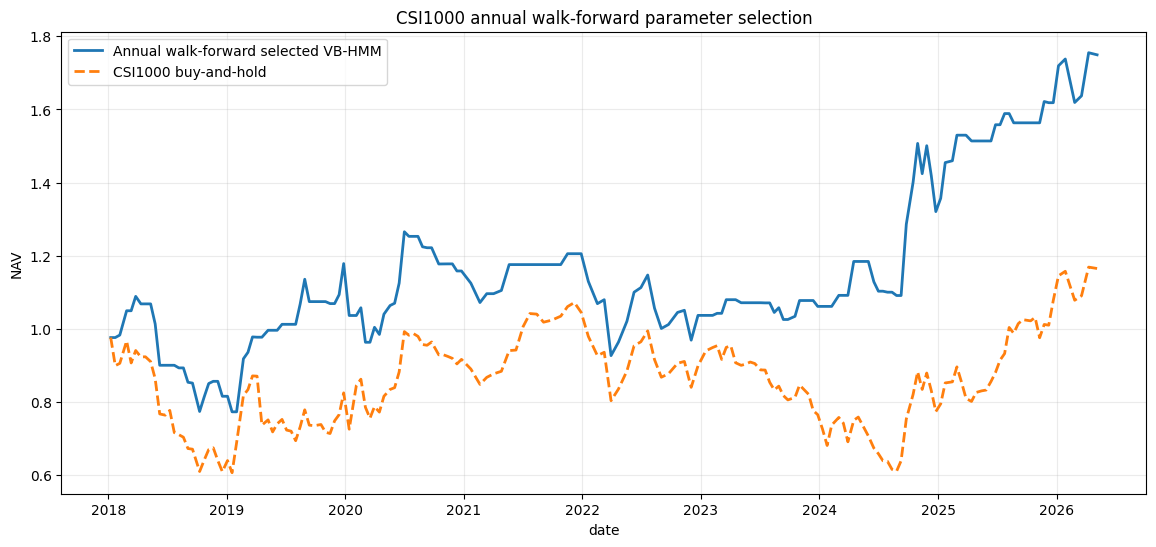

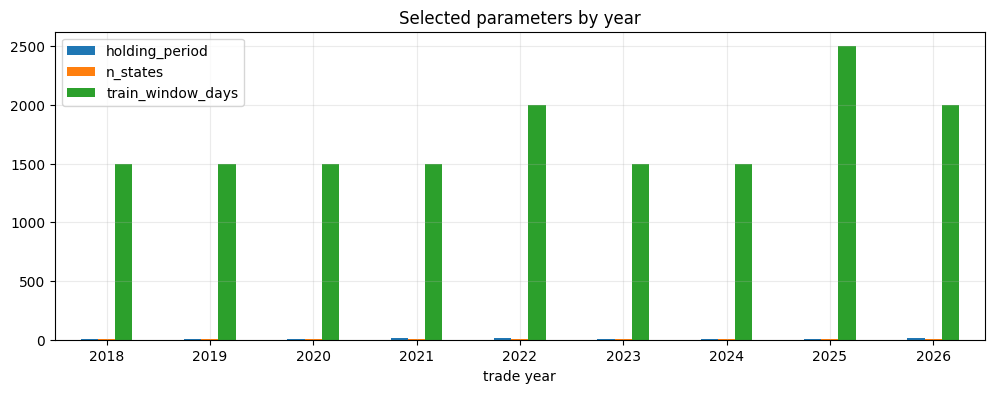

In [349]:
# 3. 拼接每年样本外表现，形成年度动态选参策略净值。
if wf_oos_bt.empty:
    raise RuntimeError("wf_oos_bt is empty. Check candidate grid or date windows.")

wf_oos_bt = wf_oos_bt.sort_values("date").drop_duplicates(subset=["date"], keep="last").reset_index(drop=True)
wf_oos_bt["strategy_nav"] = (1 + wf_oos_bt["strategy_ret"]).cumprod()
wf_oos_bt["benchmark_nav"] = (1 + wf_oos_bt["benchmark_ret"]).cumprod()

# 注意：动态 holding_period 下每年周期长度不同，整体年化用平均周期长度近似。
avg_holding_period = wf_oos_bt["holding_period"].mean()
periods_per_year_wf = 252 / avg_holding_period

wf_summary = pd.DataFrame(
    [
        summarize_strategy(wf_oos_bt["strategy_ret"], wf_oos_bt["strategy_nav"], periods_per_year_wf),
        summarize_strategy(wf_oos_bt["benchmark_ret"], wf_oos_bt["benchmark_nav"], periods_per_year_wf),
    ],
    index=["年度动态选参 VB-HMM", "中证1000买入持有"],
)

display(wf_summary)
display(wf_oos_bt.head())
display(wf_oos_bt.tail())

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(wf_oos_bt["date"], wf_oos_bt["strategy_nav"], label="Annual walk-forward selected VB-HMM", linewidth=2)
ax.plot(wf_oos_bt["date"], wf_oos_bt["benchmark_nav"], label="CSI1000 buy-and-hold", linestyle="--", linewidth=2)
ax.set_title("CSI1000 annual walk-forward parameter selection")
ax.set_xlabel("date")
ax.set_ylabel("NAV")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
wf_selection_table.set_index("trade_year")[["holding_period", "n_states", "train_window_days"]].plot(kind="bar", ax=ax)
ax.set_title("Selected parameters by year")
ax.set_xlabel("trade year")
ax.tick_params(axis="x", rotation=0)
plt.show()


## 12. 多标的：年度动态选参 walk-forward


In [350]:
def run_annual_walk_forward_for_asset(symbol, asset_name, base_cfg):
    param_grid = list(product(HOLDING_PERIOD_GRID, N_STATES_GRID, TRAIN_WINDOW_GRID))
    candidate_cache = {}
    candidate_summary_rows = []

    for holding_period, n_states, train_window_days in param_grid:
        key = (holding_period, n_states, train_window_days)
        print(f"[{asset_name}] candidate h={holding_period}, n={n_states}, train_window={train_window_days}")
        candidate_cfg = make_cfg_for_params(
            symbol,
            holding_period,
            n_states,
            train_window_days,
            base_cfg,
        )

        try:
            result, _ = run_vb_hmm_backtest_for_symbol(symbol, asset_name, candidate_cfg)
        except Exception as exc:
            print(f"  failed: {type(exc).__name__}: {exc}")
            continue

        if result is None:
            print("  skipped: no valid prediction rows")
            continue

        row, bt_candidate = result
        bt_candidate = bt_candidate.copy()
        bt_candidate["asset"] = asset_name
        bt_candidate["symbol"] = symbol
        bt_candidate["holding_period"] = holding_period
        bt_candidate["n_states"] = n_states
        bt_candidate["train_window_days"] = train_window_days

        candidate_cache[key] = bt_candidate
        row.update(
            {
                "asset": asset_name,
                "symbol": symbol,
                "holding_period": holding_period,
                "n_states": n_states,
                "train_window_days": train_window_days,
            }
        )
        candidate_summary_rows.append(row)

    if not candidate_cache:
        return {
            "asset": asset_name,
            "symbol": symbol,
            "candidate_summary": pd.DataFrame(candidate_summary_rows),
            "selection_table": pd.DataFrame(),
            "oos_bt": pd.DataFrame(),
            "summary": pd.DataFrame(),
        }

    selection_rows = []
    oos_slices = []

    for trade_year in range(WF_FIRST_TRADE_YEAR, pd.to_datetime(base_cfg.end_date).year + 1):
        validation_start = pd.Timestamp(f"{trade_year - WF_VALIDATION_YEARS}-01-01")
        validation_end = pd.Timestamp(f"{trade_year - 1}-12-31")
        trade_start = pd.Timestamp(f"{trade_year}-01-01")
        trade_end = min(pd.Timestamp(f"{trade_year}-12-31"), pd.to_datetime(base_cfg.end_date))

        validation_rows = []
        for (holding_period, n_states, train_window_days), bt_candidate in candidate_cache.items():
            validation_slice = bt_candidate[
                (bt_candidate["date"] >= validation_start)
                & (bt_candidate["date"] <= validation_end)
            ].copy()
            metrics = summarize_bt_slice(validation_slice, holding_period)
            if metrics is None:
                continue
            metrics.update(
                {
                    "asset": asset_name,
                    "symbol": symbol,
                    "trade_year": trade_year,
                    "validation_start": validation_start,
                    "validation_end": validation_end,
                    "holding_period": holding_period,
                    "n_states": n_states,
                    "train_window_days": train_window_days,
                }
            )
            validation_rows.append(metrics)

        validation_table = pd.DataFrame(validation_rows)
        if validation_table.empty:
            print(f"[{asset_name}] {trade_year}: no validation candidates")
            continue

        scored = score_parameter_candidates(validation_table)
        best = scored.iloc[0].copy()
        key = (int(best["holding_period"]), int(best["n_states"]), int(best["train_window_days"]))
        selected_bt = candidate_cache[key]
        oos_slice = selected_bt[
            (selected_bt["date"] >= trade_start)
            & (selected_bt["date"] <= trade_end)
        ].copy()

        if oos_slice.empty:
            print(f"[{asset_name}] {trade_year}: selected {key}, but no OOS rows")
            continue

        oos_slice["selected_for_year"] = trade_year
        oos_slice["selected_score"] = best["score"]
        oos_slices.append(oos_slice)

        oos_metrics = summarize_bt_slice(oos_slice, key[0])
        selection_rows.append(
            {
                "asset": asset_name,
                "symbol": symbol,
                "trade_year": trade_year,
                "validation_start": validation_start,
                "validation_end": validation_end,
                "trade_start": trade_start,
                "trade_end": trade_end,
                "holding_period": key[0],
                "n_states": key[1],
                "train_window_days": key[2],
                "validation_score": best["score"],
                "validation_total_return": best["strategy_total_return"],
                "validation_max_drawdown": best["strategy_max_drawdown"],
                "validation_direction_accuracy": best["direction_accuracy"],
                "oos_total_return": oos_metrics["strategy_total_return"],
                "oos_max_drawdown": oos_metrics["strategy_max_drawdown"],
                "oos_direction_accuracy": oos_metrics["direction_accuracy"],
                "oos_benchmark_total_return": oos_metrics["benchmark_total_return"],
                "oos_benchmark_max_drawdown": oos_metrics["benchmark_max_drawdown"],
                "oos_trade_count": oos_metrics["trade_count"],
            }
        )

    selection_table = pd.DataFrame(selection_rows)
    oos_bt = pd.concat(oos_slices, ignore_index=True) if oos_slices else pd.DataFrame()

    if not oos_bt.empty:
        oos_bt = oos_bt.sort_values("date").drop_duplicates(subset=["date"], keep="last").reset_index(drop=True)
        oos_bt["strategy_nav"] = (1 + oos_bt["strategy_ret"]).cumprod()
        oos_bt["benchmark_nav"] = (1 + oos_bt["benchmark_ret"]).cumprod()
        periods_per_year = 252 / oos_bt["holding_period"].mean()
        summary = pd.DataFrame(
            [
                summarize_strategy(oos_bt["strategy_ret"], oos_bt["strategy_nav"], periods_per_year),
                summarize_strategy(oos_bt["benchmark_ret"], oos_bt["benchmark_nav"], periods_per_year),
            ],
            index=["年度动态选参 VB-HMM", f"{asset_name}买入持有"],
        )
        summary["asset"] = asset_name
        summary["symbol"] = symbol
    else:
        summary = pd.DataFrame()

    return {
        "asset": asset_name,
        "symbol": symbol,
        "candidate_summary": pd.DataFrame(candidate_summary_rows),
        "selection_table": selection_table,
        "oos_bt": oos_bt,
        "summary": summary,
    }


In [ ]:
# 多标的年度动态选参。
# 这一步计算量很大：资产数量 * 参数组合数量 都会触发完整滚动回测。
# 若想先试小样本，可以临时把 WF_INDEX_POOL 改成 {"中证1000": "sh000852", "沪深300": "sh000300"}。
WF_INDEX_POOL = INDEX_POOL.copy()

wf_multi_results = {}
wf_multi_selection_tables = []
wf_multi_summary_tables = []

for asset_name, symbol in WF_INDEX_POOL.items():
    print(f"==== Annual walk-forward: {asset_name} / {symbol} ====")
    result = run_annual_walk_forward_for_asset(symbol, asset_name, cfg)
    wf_multi_results[asset_name] = result

    if not result["selection_table"].empty:
        wf_multi_selection_tables.append(result["selection_table"])
    if not result["summary"].empty:
        wf_multi_summary_tables.append(result["summary"])

wf_multi_selection_table = (
    pd.concat(wf_multi_selection_tables, ignore_index=True)
    if wf_multi_selection_tables
    else pd.DataFrame()
)
wf_multi_summary = (
    pd.concat(wf_multi_summary_tables)
    if wf_multi_summary_tables
    else pd.DataFrame()
)

display(wf_multi_selection_table)
display(wf_multi_summary)


夏普比率                                                     \
类型      上证50买入持有  上证指数买入持有 中证1000买入持有 中证500买入持有 中证800买入持有  创业板指买入持有   
asset                                                                 
上证50   -0.017305       NaN        NaN       NaN       NaN       NaN   
上证指数         NaN  0.157749        NaN       NaN       NaN       NaN   
中证1000       NaN       NaN   0.078002       NaN       NaN       NaN   
中证500        NaN       NaN        NaN  0.159595       NaN       NaN   
中证800        NaN       NaN        NaN       NaN  0.082303       NaN   
创业板指         NaN       NaN        NaN       NaN       NaN  0.414598   
沪深300        NaN       NaN        NaN       NaN       NaN       NaN   
深证成指         NaN       NaN        NaN       NaN       NaN       NaN   

                                             年化收益率  ...      总收益率      最大回撤  \
类型     年度动态选参 VB-HMM 沪深300买入持有  深证成指买入持有  上证50买入持有  ...  深证成指买入持有  上证50买入持有   
asset                                               ...                       
上证50        0.070837       NaN       NaN -0.002833  ...       NaN  0.436835   
上证指数        0.071975       NaN       NaN       NaN  ...       NaN       NaN   
中证1000      0.364692       NaN       NaN       NaN  ...       NaN       NaN   
中证500      -0.076096       NaN       NaN       NaN  ...       NaN       NaN   
中证800       0.131255       NaN       NaN       NaN  ...       NaN       NaN   
创业板指        0.502266       NaN       NaN       NaN  ...       NaN       NaN   
沪深300       0.007102  0.101284       NaN       NaN  ...       NaN       NaN   
深证成指       -0.066466       NaN  0.155417       NaN  ...  0.321639       NaN   

                                                                        \
类型      上证指数买入持有 中证1000买入持有 中证500买入持有 中证800买入持有 创业板指买入持有 年度动态选参 VB-HMM   
asset                                                                    
上证50         NaN        NaN       NaN       NaN      NaN      0.270782   
上证指数    0.274011        NaN       NaN       NaN      NaN      0.277356   
中证1000       NaN    0.43085       NaN       NaN      NaN      0.290236   
中证500        NaN        NaN  0.400226       NaN      NaN      0.392300   
中证800        NaN        NaN       NaN  0.411862      NaN      0.355331   
创业板指         NaN        NaN       NaN       NaN  0.55971      0.479729   
沪深300        NaN        NaN       NaN       NaN      NaN      0.374758   
深证成指         NaN        NaN       NaN       NaN      NaN      0.573467   

                           
类型     沪深300买入持有 深证成指买入持有  
asset                      
上证50         NaN      NaN  
上证指数         NaN      NaN  
中证1000       NaN      NaN  
中证500        NaN      NaN  
中证800        NaN      NaN  
创业板指         NaN      NaN  
沪深300    0.44888      NaN  
深证成指         NaN  0.48314  

[8 rows x 36 columns]

/Users/zhu/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/zhu/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 35777 (\N{CJK UNIFIED IDEOGRAPH-8BC1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/zhu/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 27818 (\N{CJK UNIFIED IDEOGRAPH-6CAA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/zhu/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 28145 (\N{CJK UNIFIED IDEOGRAPH-6DF1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/zhu/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 20013

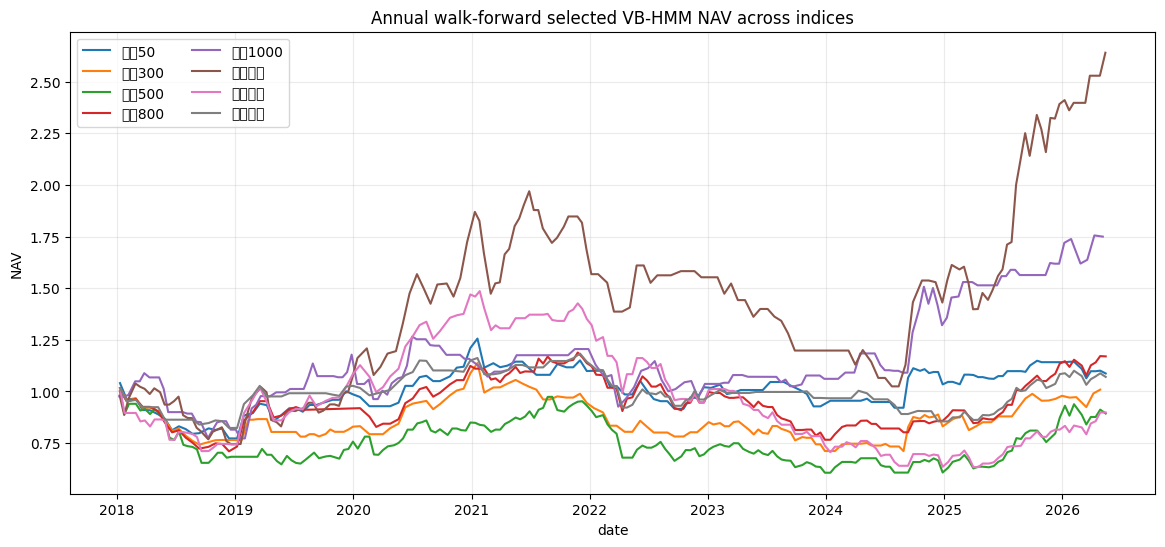

In [352]:
if not wf_multi_summary.empty:
    summary_wide = (
        wf_multi_summary
        .reset_index()
        .rename(columns={"index": "类型"})
        .pivot(index="asset", columns="类型", values=["夏普比率", "年化收益率", "总收益率", "最大回撤"])
    )
    display(summary_wide)

fig, ax = plt.subplots(figsize=(14, 6))
for asset_name, result in wf_multi_results.items():
    oos_bt_asset = result["oos_bt"]
    if oos_bt_asset.empty:
        continue
    ax.plot(oos_bt_asset["date"], oos_bt_asset["strategy_nav"], label=asset_name)
ax.set_title("Annual walk-forward selected VB-HMM NAV across indices")
ax.set_xlabel("date")
ax.set_ylabel("NAV")
ax.legend(ncol=2)
plt.show()


Using Chinese font: Arial Unicode MS


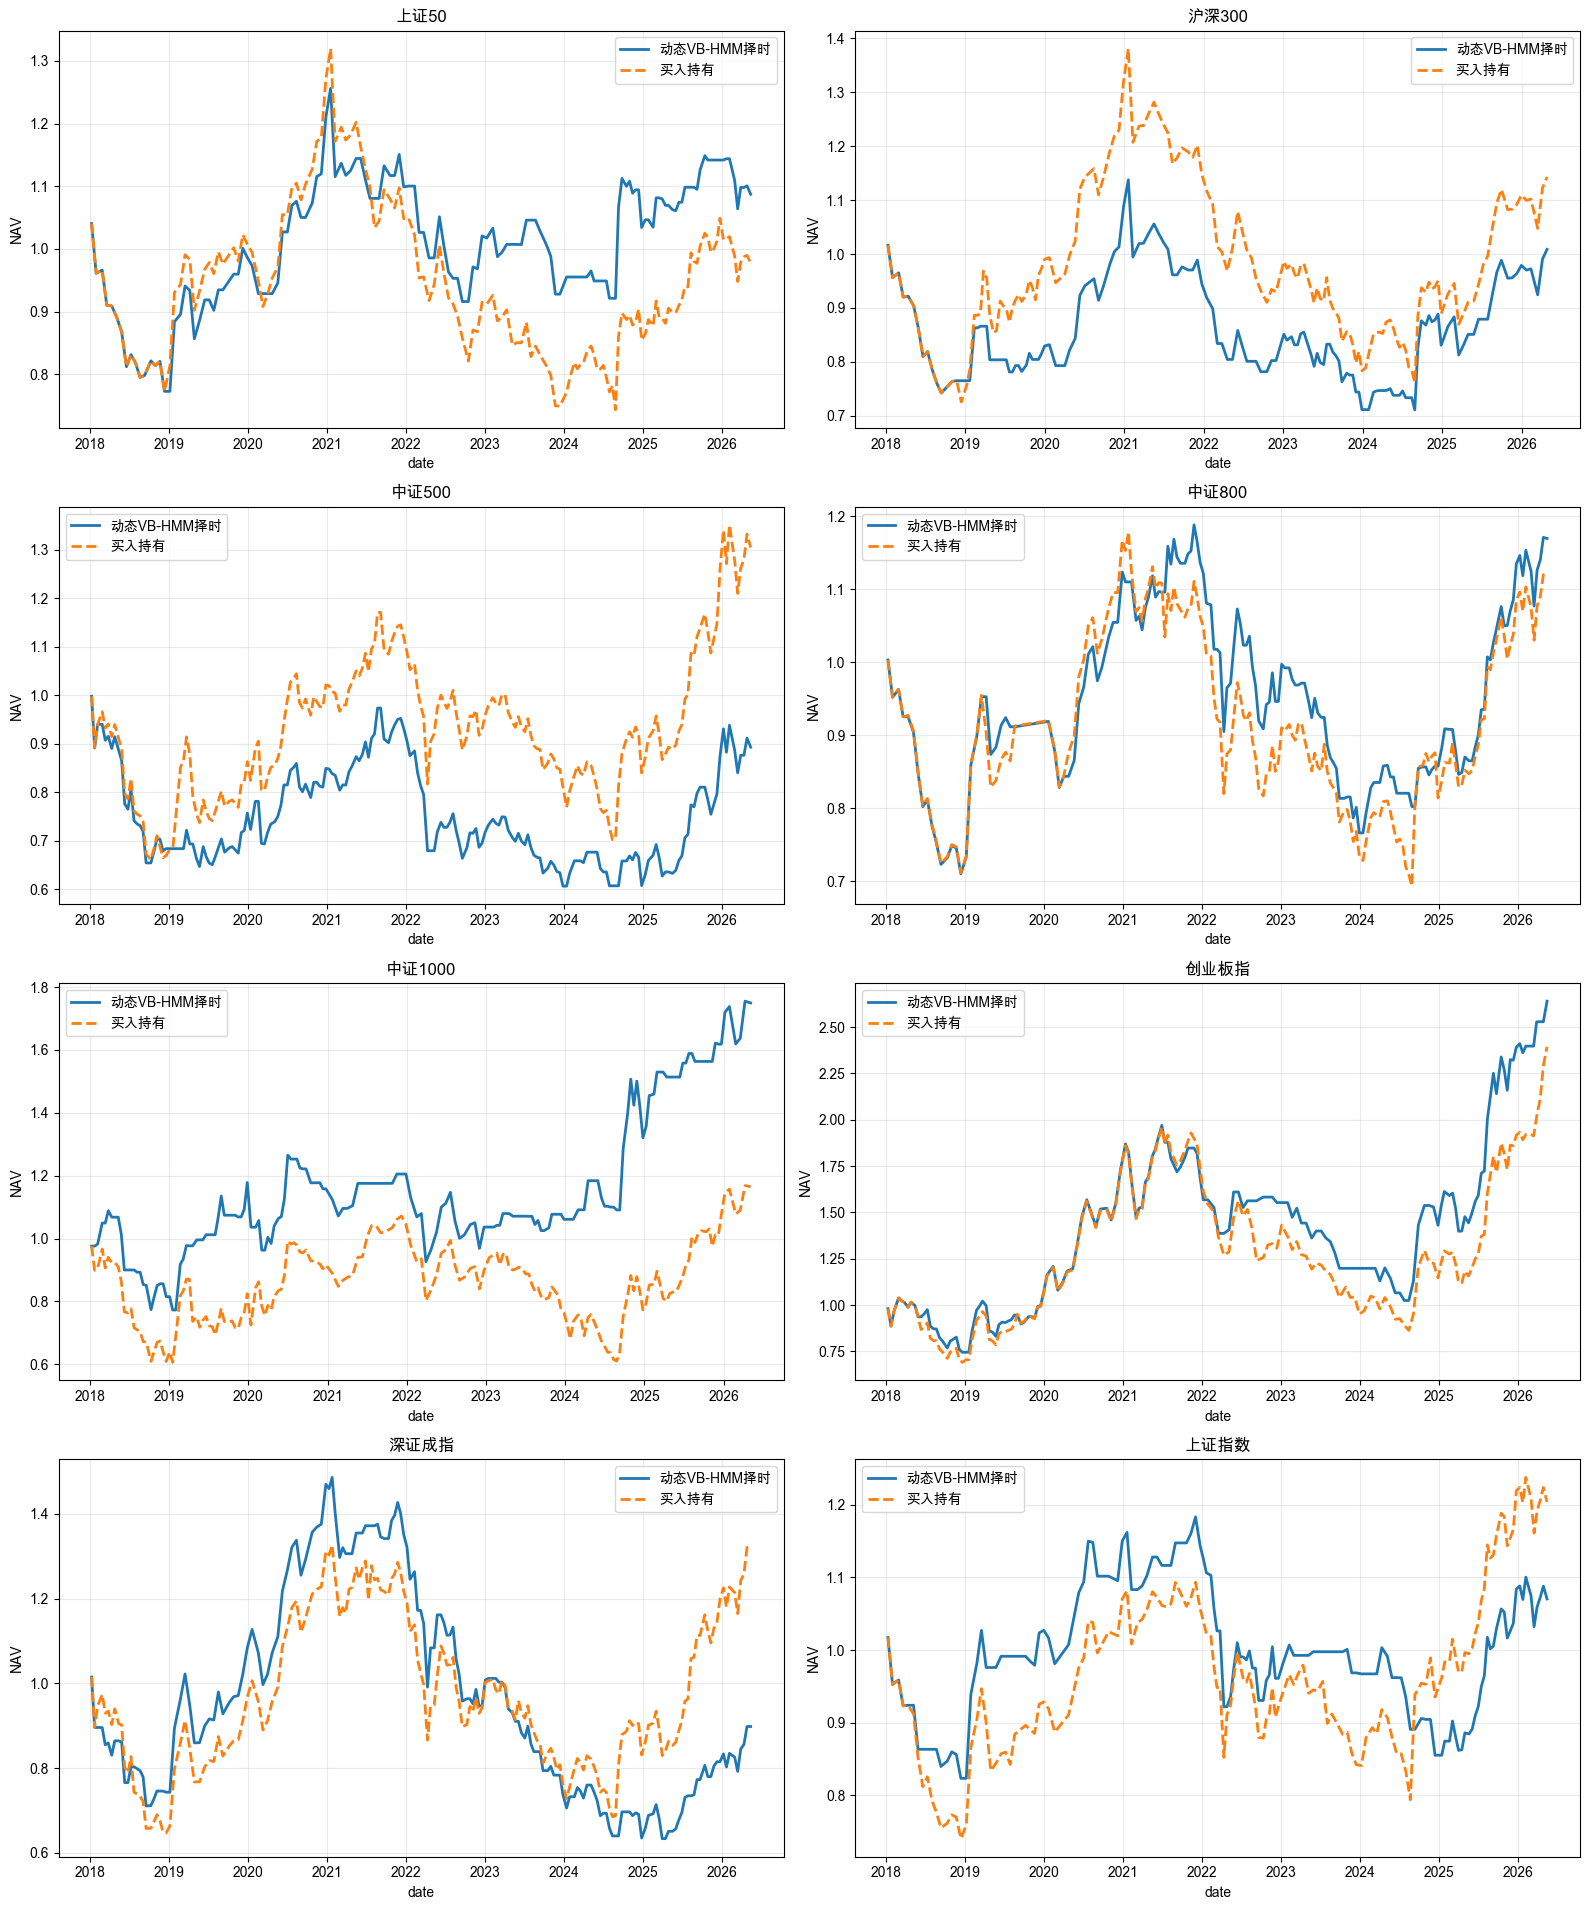

In [355]:
# 支持中文显示
import matplotlib.pyplot as plt
from matplotlib import font_manager

candidate_fonts = [
    "Arial Unicode MS",
    "PingFang SC",
    "Heiti SC",
    "Songti SC",
    "STHeiti",
    "SimHei",
]

available_fonts = {f.name for f in font_manager.fontManager.ttflist}

for font in candidate_fonts:
    if font in available_fonts:
        plt.rcParams["font.sans-serif"] = [font]
        plt.rcParams["axes.unicode_minus"] = False
        print(f"Using Chinese font: {font}")
        break
else:
    print("No common Chinese font found. Chinese labels may still not display.")

# 每个资产单独画：年度动态选参 VB-HMM vs 买入持有
import math
asset_name=["SSE50","CSI300","CSI500","CSI800","CSI1000","ChiNext","SZ Component","SSE Composite"]
plot_items = [
    (asset_name, result["oos_bt"])
    for asset_name, result in wf_multi_results.items()
    if (result is not None) and (not result["oos_bt"].empty)
]

n_assets = len(plot_items)
n_cols = 2
n_rows = math.ceil(n_assets / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 4.8 * n_rows),
    squeeze=False,
)

for ax, (asset_name, oos_bt_asset) in zip(axes.ravel(), plot_items):
    bt_plot = oos_bt_asset.sort_values("date").copy()

    # 保险起见：重新按该资产自己的样本外收益计算净值
    bt_plot["strategy_nav_plot"] = (1 + bt_plot["strategy_ret"]).cumprod()
    bt_plot["benchmark_nav_plot"] = (1 + bt_plot["benchmark_ret"]).cumprod()

    ax.plot(
        bt_plot["date"],
        bt_plot["strategy_nav_plot"],
        label="动态VB-HMM择时",
        linewidth=2,
    )
    ax.plot(
        bt_plot["date"],
        bt_plot["benchmark_nav_plot"],
        label="买入持有",
        linestyle="--",
        linewidth=2,
    )

    ax.set_title(asset_name)
    ax.set_xlabel("date")
    ax.set_ylabel("NAV")
    ax.grid(alpha=0.25)
    ax.legend()

# 删除多余空子图
for ax in axes.ravel()[len(plot_items):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()